# Pertemuan 7 — Tugas: Multiple Linear Regression pada Dataset Medical Cost Personal

Tugas ini menerapkan regresi linier berganda pada dataset Medical Cost Personal Datasets. Ketentuan tugas:

1. Mengidentifikasi variabel bebas (fitur) dan variabel target berupa biaya medis personal.
2. Membagi dataset menjadi data latih dan data uji.
3. Melakukan feature scaling bila diperlukan.
4. Membuat model multiple linear regression dengan scikit-learn.
5. Melatih model dan melakukan prediksi pada data uji.
6. Mengevaluasi model dengan R-squared, MSE, dan MAE.
7. Menjelaskan dataset dan menganalisis hasil yang diperoleh.

Sebagai pelengkap, pada bagian akhir tugas ditambahkan perbandingan dengan Support Vector Regression sesuai arahan umum tugas.

Sumber: [Tugas Praktikum](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-regresi/tugas-praktikum).

## 1. Import library

Sel berikut memuat pustaka untuk pengolahan data, visualisasi, pemodelan, dan evaluasi.

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

## 2. Memuat dataset dan deskripsi variabel

Dataset Medical Cost Personal memuat 1.338 catatan pemegang asuransi kesehatan beserta biaya medis tahunan. Variabel target adalah `charges`, sedangkan variabel bebasnya meliputi usia, jenis kelamin, indeks massa tubuh, jumlah anak, status merokok, dan wilayah tempat tinggal.

In [2]:
# Memuat dataset
data = pd.read_csv('insurance.csv')

display(data.head())

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 3. Eksplorasi data awal

Ukuran data, tipe kolom, keberadaan nilai kosong, dan ringkasan statistik diperiksa untuk memastikan data siap dipakai. Dataset ini memuat tiga kolom kategorikal, yaitu `sex`, `smoker`, dan `region`, yang perlu diubah menjadi bentuk numerik sebelum dipakai model regresi.

In [3]:
print("Ukuran data:", data.shape)
print()
print("Informasi data:")
data.info()
print()
print("Jumlah nilai kosong per kolom:")
display(data.isnull().sum().to_frame('jumlah_kosong'))
print("Deskripsi statistik:")
display(data.describe().round(2))

Ukuran data: (1338, 7)

Informasi data:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

Jumlah nilai kosong per kolom:


,jumlah_kosong
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


Deskripsi statistik:


,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


## 4. Visualisasi data

Sebaran biaya medis digambarkan dengan histogram, sedangkan hubungan antara usia dan indeks massa tubuh terhadap biaya medis digambarkan dengan scatter plot yang dipisahkan menurut status merokok. Pola pada scatter plot membantu memahami variabel mana yang berpengaruh besar terhadap biaya medis.

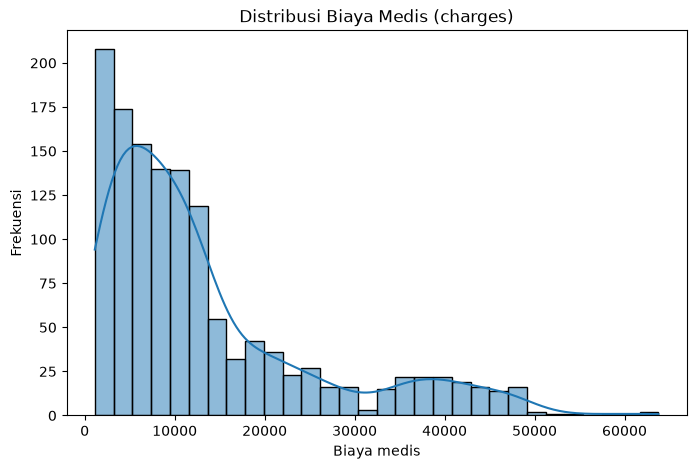

In [4]:
# Distribusi biaya medis
plt.figure(figsize=(8, 5))
sns.histplot(data['charges'], bins=30, kde=True)
plt.title('Distribusi Biaya Medis (charges)')
plt.xlabel('Biaya medis')
plt.ylabel('Frekuensi')
plt.show()

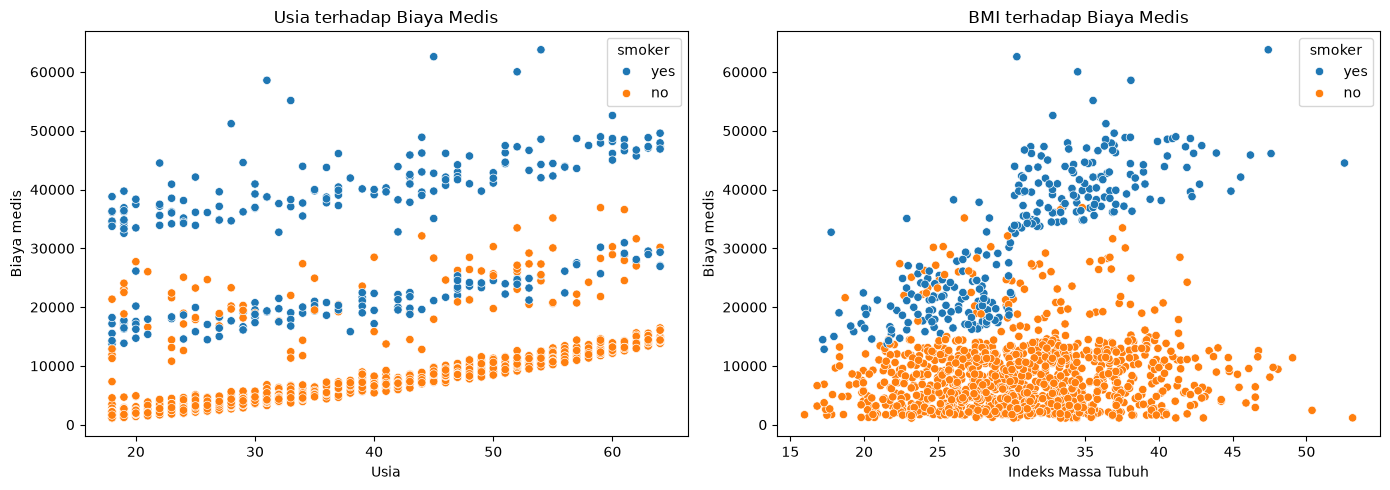

In [5]:
# Hubungan usia dan BMI terhadap biaya medis menurut status merokok
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=data, x='age', y='charges', hue='smoker', ax=axes[0])
axes[0].set_title('Usia terhadap Biaya Medis')
axes[0].set_xlabel('Usia')
axes[0].set_ylabel('Biaya medis')

sns.scatterplot(data=data, x='bmi', y='charges', hue='smoker', ax=axes[1])
axes[1].set_title('BMI terhadap Biaya Medis')
axes[1].set_xlabel('Indeks Massa Tubuh')
axes[1].set_ylabel('Biaya medis')

plt.tight_layout()
plt.show()

Matriks korelasi antar variabel numerik ditampilkan untuk melihat kekuatan hubungan setiap fitur terhadap biaya medis.

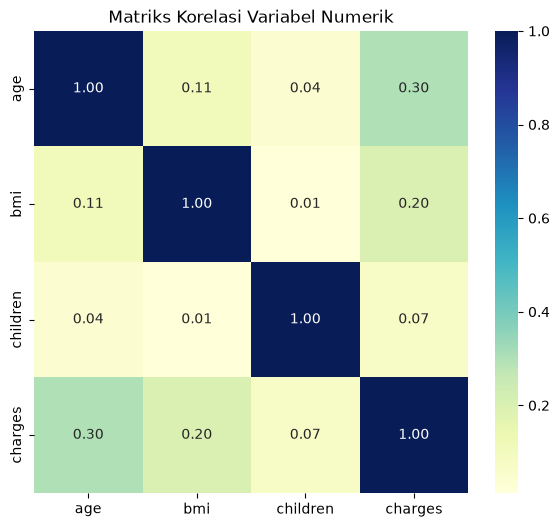

In [6]:
plt.figure(figsize=(7, 6))
sns.heatmap(data.select_dtypes(include='number').corr(), cmap='YlGnBu', annot=True, fmt=".2f")
plt.title('Matriks Korelasi Variabel Numerik')
plt.show()

## 5. Encoding variabel kategorikal

Variabel `sex`, `smoker`, dan `region` diubah menjadi kolom indikator dengan `pd.get_dummies`. Parameter `drop_first=True` dipakai untuk menghindari kolom yang saling bergantung (dummy trap) yang dapat mengganggu penafsiran koefisien.

In [7]:
# Encoding variabel kategorikal
data_encoded = pd.get_dummies(data, columns=['sex', 'smoker', 'region'], drop_first=True)

display(data_encoded.head())
print("Kolom setelah encoding:", list(data_encoded.columns))

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


Kolom setelah encoding: ['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


## 6. Pembagian data latih dan data uji

Variabel target `charges` dipisahkan dari variabel bebas. Data kemudian dibagi menjadi 80% data latih dan 20% data uji dengan `random_state` tetap agar hasil dapat diulang.

In [8]:
X = data_encoded.drop(columns='charges')
y = data_encoded['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Ukuran data latih:", X_train.shape)
print("Ukuran data uji  :", X_test.shape)

Ukuran data latih: (1070, 8)
Ukuran data uji  : (268, 8)


## 7. Feature scaling

Regresi linier berganda berbasis metode kuadrat terkecil tidak mewajibkan penskalaan fitur karena koefisiennya tidak dipengaruhi skala. Meskipun demikian, penskalaan tetap diterapkan agar model dapat dibandingkan secara adil dengan SVR pada bagian akhir. Data latih dan data uji diskalakan dengan `StandardScaler` yang dilatih hanya pada data latih.

In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 8. Model Multiple Linear Regression

Model regresi linier berganda dilatih pada seluruh fitur yang telah diskalakan, kemudian dipakai untuk memprediksi biaya medis pada data uji.

In [10]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

## 9. Evaluasi model

Kinerja model diukur dengan R-squared, MSE, RMSE, dan MAE. Nilai R-squared menunjukkan proporsi keragaman biaya medis yang dapat dijelaskan model, sedangkan MSE, RMSE, dan MAE menunjukkan besarnya kesalahan prediksi dalam satuan dolar.

In [11]:
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print(f"R-squared : {r2:.4f}")
print(f"MSE       : {mse:.2f}")
print(f"RMSE      : {rmse:.2f}")
print(f"MAE       : {mae:.2f}")

R-squared : 0.7836
MSE       : 33596915.85
RMSE      : 5796.28
MAE       : 4181.19


## 10. Visualisasi hasil prediksi

Nilai sebenarnya dan nilai prediksi digambarkan pada satu bidang. Titik yang mendekati garis diagonal menunjukkan prediksi yang akurat.

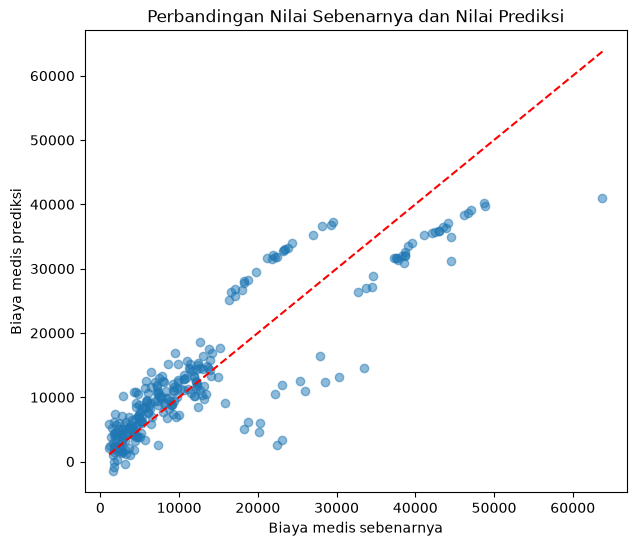

In [12]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Biaya medis sebenarnya')
plt.ylabel('Biaya medis prediksi')
plt.title('Perbandingan Nilai Sebenarnya dan Nilai Prediksi')
plt.show()

## 11. Analisis koefisien model

Koefisien setiap fitur menunjukkan arah dan besar pengaruhnya terhadap biaya medis. Karena fitur telah diskalakan, besar koefisien dapat dibandingkan langsung antar fitur. Koefisien diurutkan dari yang paling berpengaruh.

In [13]:
koefisien = pd.DataFrame({
    'Fitur': X.columns,
    'Koefisien': model.coef_,
}).sort_values('Koefisien', key=abs, ascending=False)

display(koefisien.reset_index(drop=True).round(2))
print(f"Intercept: {model.intercept_:.2f}")

,Fitur,Koefisien
0,smoker_yes,9558.48
1,age,3614.98
2,bmi,2036.23
3,children,516.89
4,region_southwest,-349.11
5,region_southeast,-290.16
6,region_northwest,-158.14
7,sex_male,-9.29


Intercept: 13346.09


## 12. Perbandingan dengan SVR

Sebagai pembanding, SVR berkernel RBF dilatih pada data yang sama. Fitur dan target diskalakan terlebih dahulu karena SVR peka terhadap skala data. Hasil kedua model dibandingkan pada tabel agar perbedaan kinerjanya terlihat jelas.

In [14]:
sc_y = StandardScaler()
y_train_scaled = sc_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()

svr = SVR(kernel='rbf')
svr.fit(X_train_scaled, y_train_scaled)
y_pred_svr = sc_y.inverse_transform(svr.predict(X_test_scaled).reshape(-1, 1)).ravel()

perbandingan = pd.DataFrame({
    'Model': ['Multiple Linear Regression', 'SVR (RBF)'],
    'R-squared': [round(r2, 4), round(r2_score(y_test, y_pred_svr), 4)],
    'MSE': [round(mse, 2), round(mean_squared_error(y_test, y_pred_svr), 2)],
    'MAE': [round(mae, 2), round(mean_absolute_error(y_test, y_pred_svr), 2)],
})

display(perbandingan)

,Model,R-squared,MSE,MAE
0,Multiple Linear Regression,0.7836,33596915.85,4181.19
1,SVR (RBF),0.8623,21380312.05,2462.45


## Kesimpulan

Model multiple linear regression pada dataset Medical Cost Personal menghasilkan R-squared sebesar 0,7836, yang berarti sekitar 78% keragaman biaya medis dapat dijelaskan oleh fitur yang dipakai. Nilai MAE 4.181,19 dolar dan RMSE 5.796,28 dolar menunjukkan rata-rata kesalahan prediksi yang cukup besar karena sebaran biaya medis sangat lebar, mulai dari ribuan hingga puluhan ribu dolar. Analisis koefisien memperlihatkan status merokok sebagai faktor paling berpengaruh terhadap kenaikan biaya medis, diikuti usia dan indeks massa tubuh. SVR berkernel RBF yang dilatih pada data terskalakan menghasilkan kinerja lebih baik pada data uji, sehingga hubungan antara fitur dan biaya medis tidak sepenuhnya linier. Penskalaan fitur tidak mengubah hasil regresi linier, tetapi diperlukan agar perbandingan dengan SVR menjadi adil.